Import Pandas

In [32]:
import pandas as pd

Read CSV file using Pandas

In [33]:
df = pd.read_csv("Mall_Customers.csv")
print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


Check dataframe information

In [ ]:
print(df.info()) #display column names, not null count and data type
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Drop Null values from dataframe

In [35]:
df.dropna(inplace=True)

Import LabelEncoder for transform gender value to integer

In [37]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

Display information of dataframe

In [38]:
print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1       1   19                  15                      39
1             2       1   21                  15                      81
2             3       0   20                  16                       6
3             4       0   23                  16                      77
4             5       0   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196       0   35                 120                      79
196         197       0   45                 126                      28
197         198       1   32                 126                      74
198         199       1   32                 137                      18
199         200       1   30                 137                      83

[200 rows x 5 columns]


import seaborn and matplotlib for graphical representation

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

Plot Annual Income Distribution Histogram

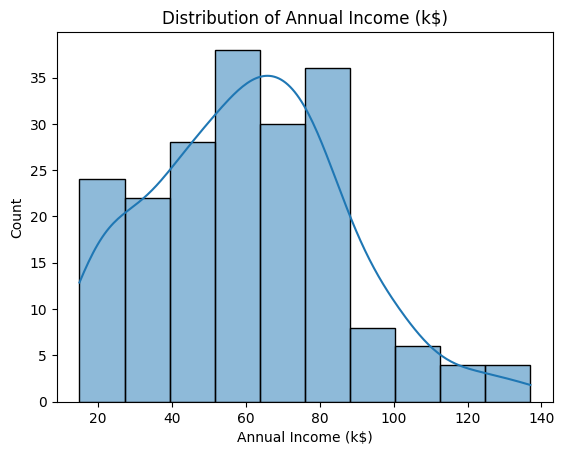

In [40]:
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title("Distribution of Annual Income (k$)")
plt.show()

Plot Spending Score Distribution Histogram

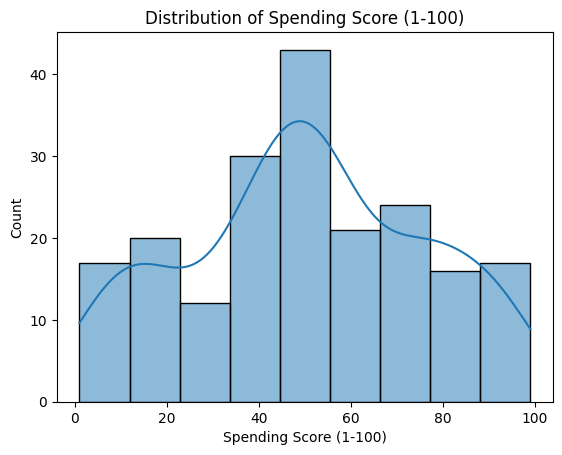

In [41]:
sns.histplot(df['Spending Score (1-100)'], kde=True)
plt.title("Distribution of Spending Score (1-100)")
plt.show()

Import Kmean for making clusters

In [42]:
from sklearn.cluster import KMeans

Apply Elbow Method to find the optimal k

In [47]:
values = df[["Annual Income (k$)", "Spending Score (1-100)"]]
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters = k, random_state = 42)
    model.fit(values)
    inertia.append(model.inertia_)

Plot the elbow curve

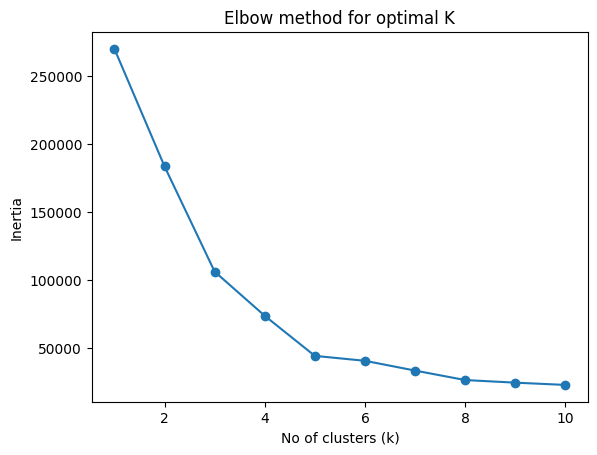

In [44]:
plt.plot(range(1, 11), inertia, marker = "o")
plt.xlabel("No of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method for optimal K")
plt.show()

Apply KMeans with optimal k

In [45]:
kmean = KMeans(n_clusters = 5, random_state = 42)
df['Cluster'] = kmean.fit_predict(values)

Visualize Final Clusters using Scatter plot with cluster color

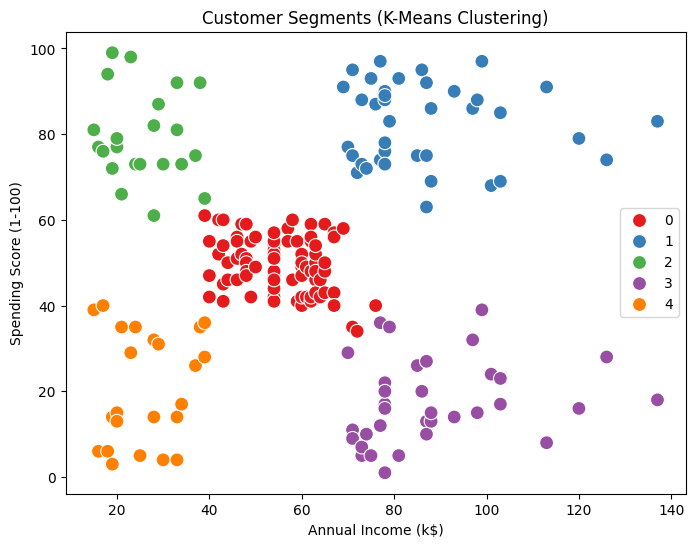

In [46]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='Set1', s=100)
plt.title("Customer Segments (K-Means Clustering)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()